# <a id='toc1_'></a>[Tempo de chegada e desvio de feixe](#toc0_)

**Sumário**<a id='toc0_'></a>    
- [Tempo de chegada e desvio de feixe](#toc1_)    
  - [Introdução](#toc1_1_)    
  - [Desenvolvimento](#toc1_2_)    
    - [Atributos triviais](#toc1_2_1_)    
    - [Atributos geográficos](#toc1_2_2_)    
    - [Fator de amplitude](#toc1_2_3_)    
    - [Pipeline de processamento](#toc1_2_4_)    
    - [Escolha de terremotos](#toc1_2_5_)    
      - [Terremotos com magnitude alta (2020-2026)](#toc1_2_5_1_)    
      - [Terremotos na América Latina](#toc1_2_5_2_)    
    - [Análises finais](#toc1_2_6_)    
  - [Conclusão](#toc1_3_)    
  - [Referências](#toc1_4_)    

<!-- vscode-jupyter-toc-config
	numbering=false
	anchor=true
	flat=false
	minLevel=1
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

## <a id='toc1_1_'></a>[Introdução](#toc0_)

Agora que temos todas as ferramentas necessárias, vamos montar o dataset que será utilizado para treinar nosso modelo. Lembrando que nem todos os atributos do dataset serão utilizados, alguns servem apenas para analisar o comportamento do modelo.

O dataset idealizado possuirá os seguintes atributos:
 - `event_id`: Indica o ID do evento
 - `magnitude`: Indica a magnitude do terremoto
 - `magnitude_type`: Indica o tipo de magnitude do terremoto
 - `depth`: Indica a profundidade do terremoto
 - `origin_time`: Indica o tempo do evento
 - `latitude`: Indica a latitude do terremoto
 - `longitude`: Indica a longitude do terremoto
 - `geodesic_distance`: Indica a distância geodésica do terremoto
 - `azimuth_degree`: Indica o azimute do terremoto
 - `epicenter_distance`: Indica a distância do epicentro do terremoto
 - `earth_water_ratio`: Indica a razão entre terra e água
 - `origin_plate`: Indica a placa tectônica do terremoto
 - `first_arrival_time_delta`: Indica o tempo de chegada estimado do primeiro sinal do terremoto
 - `arrival_time_delta`: Indica a diferença entre o primeiro e o último tempo de chegada estimado do sinal do terremoto
 - `min_amplitude`: Indica o menor valor de amplitude observado na região do sinal do terremoto
 - `max_amplitude`: Indica o maior valor de amplitude observado na região do sinal do terremoto
 - `amplitude_std`: Indica o desvio padrão da amplitude na região do sinal do terremoto
 - `amplitude_region`: Indica o intervalo de tempo utilizado para analisar o sinal do terremoto
 - `min_noise`: Indica o menor valor observado na região de ruído
 - `max_noise`: Indica o maior valor observado na região de ruído
 - `noise_std`: Indica o desvio padrão do sinal na região de ruído
 - `noise_region`: Indica o intervalo de tempo utilizado para caracterizar o ruído
 - `std_factor`: Indica a razão entre o desvio padrão do sinal do terremoto e o desvio padrão do ruído
 - `amplitude_factor`: Indica a razão entre a amplitude do sinal do terremoto e a amplitude do ruído


Muitos deles podem ser obtidos facilmente a partir dos catálogos que temos. Outros, precisarão ser calculados a partir das informações disponíveis e dados geográficos.

## <a id='toc1_2_'></a>[Desenvolvimento](#toc0_)

### <a id='toc1_2_1_'></a>[Atributos triviais](#toc0_)

Vamos começar escolhendo um terremoto apenas, e calcular seus atributos. Depois buscaremos por mais terremotos para preencher o dataset.

O terremoto escolhido nesse caso foi o de magnitude 7.67 no Panamá, ocorrido em 9 de outubro de 2026 às 17:56:07 UTC. Vamos criar um dicionário para armazenar todos os atributos que iremos calcular.

In [1]:
import importlib
import Scripts.module as md

importlib.reload(md)

<module 'Scripts.module' from 'c:\\Users\\filipi2610041\\OneDrive - ILUM ESCOLA DE CIÊNCIA\\Documentos\\ILUM\\2º SEMESTRE\\Aprendizado de Máquina - DANIEL\\TIAMAT_LOCAL\\TIAMAT\\00 - Coleta e Tratamento de Dados\\Scripts\\module.py'>

In [2]:
from obspy.clients.fdsn import Client
import obspy.core.utcdatetime as utc
from Scripts.module import analise_catalog

catalog = "USP"
client = Client(catalog)
events = client.get_events(
    starttime=utc.UTCDateTime("2026-10-09T00:00:00.000000Z"),
    endtime=utc.UTCDateTime("2026-10-09T23:59:00.000000Z"),
    minmagnitude=7.0,
)
 
event = {
    "event_id": None,
    "magnitude": None,
    "magnitude_type": None,
    "depth": None,
    "origin_time": None,
    "latitude": None,
    "longitude": None,
    "geodesic_distance": None,
    "azimuth_degree": None,
    "epicenter_distance": None,
    "earth_water_ratio": None,
    "origin_plate": None,
    "first_arrival_time_delta": None,
    "arrival_time_delta": None,
    "min_amplitude": None,
    "max_amplitude": None,
    "amplitude_std": None,
    "amplitude_region": None,
    "min_noise": None,
    "max_noise": None,
    "noise_std": None,
    "noise_region": None,
    "std_factor": None,
    "amplitude_factor": None
}

events

1 Event(s) in Catalog:
2026-10-09T17:56:07.118061Z |  +7.194,  -81.319 | 7.67 mB | manual

Agora, podemos utilizar as funções que criamos previamente para obter as informações essenciais do terremoto e os tempos de chegada estimados de cada fase.

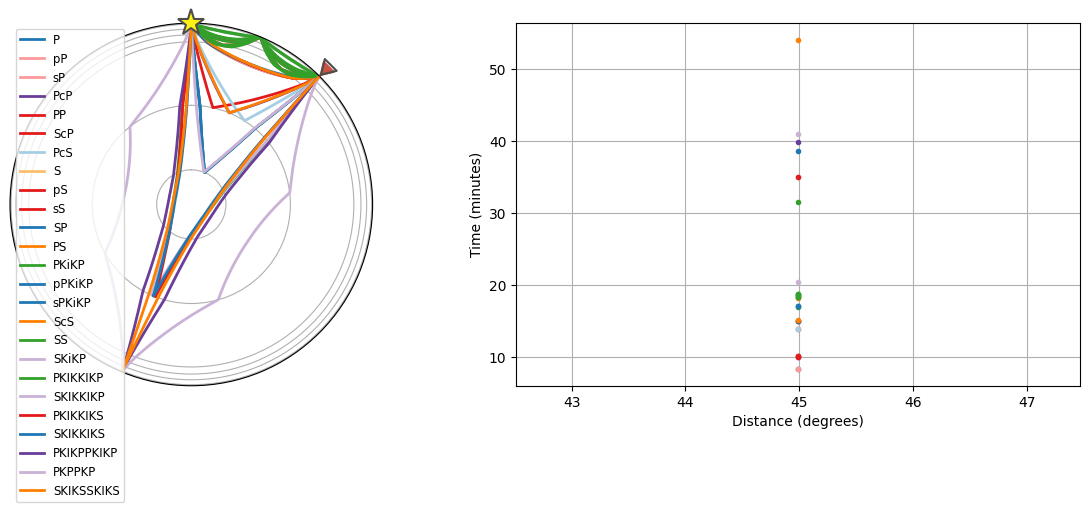

In [3]:
events_data, time_data = analise_catalog(events, catalog, plotting=True)

Essas são as informações que temos do terremoto:

In [4]:
event_data = events_data.iloc[0]
event_data

event_id              Panama2026-10-09T17:56:07.118061Z
latitude                                       7.194002
longitude                                    -81.318901
epicenter_distance                            44.986691
depth                                              12.6
magnitude                                       7.66938
magnitude_type                                       mB
Source                                              USP
origin_time                 2026-10-09T17:56:07.118061Z
receptor_latitude                            -22.807606
receptor_longitude                           -47.052526
geodesic_distance                        4994267.024232
azimuth_degree                               132.580323
Name: 0, dtype: object

Ou seja, aqui já conseguimos obter a latitude, longitude, distância de epicentro, profundidade, magnitude, tipo de magnitude, tempo do evento, distância geodésica e azimute. Vamos preencher o dicionário com essas informações.

In [5]:
event["event_id"] = event_data["event_id"]
event["latitude"] = event_data["latitude"]
event["longitude"] = event_data["longitude"]
event["epicenter_distance"] = event_data["epicenter_distance"]
event["geodesic_distance"] = event_data["geodesic_distance"]
event["azimuth_degree"] = event_data["azimuth_degree"]
event["magnitude"] = event_data["magnitude"]
event["magnitude_type"] = event_data["magnitude_type"]
event["depth"] = event_data["depth"]
event["origin_time"] = event_data["origin_time"]

Também temos os tempos de chegada estimados para cada fase, que serão utilizados para calcular o tempo de chegada do primeiro sinal do terremoto e a diferença entre o primeiro e o último tempo de chegada estimado do sinal do terremoto. Os dados de chegada estimados para cada fase são:

In [6]:
time_data

,event_id,phase,takeoff_angle,frequency,incidente_angle,ray_parameter,travel_time,arrival_time,model_used
0,Panama2026-10-09T17:56:07.118061Z,P,24.580301,Unknown,24.528479,456.015855,494.886675,2026-10-09T18:04:22.004736Z,iasp91
1,Panama2026-10-09T17:56:07.118061Z,pP,155.397993,Unknown,24.550134,456.393508,498.838260,2026-10-09T18:04:25.956321Z,iasp91
2,Panama2026-10-09T17:56:07.118061Z,sP,166.046287,Unknown,24.546198,456.324870,500.502155,2026-10-09T18:04:27.620216Z,iasp91
3,Panama2026-10-09T17:56:07.118061Z,PcP,10.395651,Unknown,10.374863,197.816936,595.751170,2026-10-09T18:06:02.869231Z,iasp91
4,Panama2026-10-09T17:56:07.118061Z,PP,33.754895,Unknown,33.6792,609.136112,600.121780,2026-10-09T18:06:07.239841Z,iasp91
...,...,...,...,...,...,...,...,...,...
28,Panama2026-10-09T17:56:07.118061Z,PKIKKIKS,2.840006,Unknown,1.641543,54.317362,2101.279903,2026-10-09T18:31:08.397964Z,iasp91
29,Panama2026-10-09T17:56:07.118061Z,SKIKKIKS,1.569158,Unknown,1.566054,51.820115,2312.880564,2026-10-09T18:34:39.998625Z,iasp91
30,Panama2026-10-09T17:56:07.118061Z,PKIKPPKIKP,3.777634,Unknown,3.770152,72.227477,2392.649096,2026-10-09T18:35:59.767157Z,iasp91
31,Panama2026-10-09T17:56:07.118061Z,PKPPKP,13.058158,Unknown,13.031877,247.692530,2456.711519,2026-10-09T18:37:03.829580Z,iasp91


Então, conseguimos calcular o tempo de chegada do primeiro sinal do terremoto e a diferença entre o primeiro e o último tempo de chegada estimado do sinal do terremoto da seguinte forma:

In [7]:
from datetime import datetime

def to_timestamp(value):
    if isinstance(value, str):
        value = datetime.fromisoformat(value.replace("Z", "+00:00"))
        
    if isinstance(value.timestamp, (int, float)):
        return value.timestamp

    return value.timestamp()

first_arrival_time = to_timestamp(time_data["arrival_time"].min())
last_arrival_time = to_timestamp(time_data["arrival_time"].max())

event["first_arrival_time_delta"] = first_arrival_time - event_data["origin_time"].timestamp
event["arrival_time_delta"] = last_arrival_time - first_arrival_time

Até agora, nosso dicionário está assim:

In [8]:
event

{'event_id': 'Panama2026-10-09T17:56:07.118061Z',
 'magnitude': np.float64(7.669379939464922),
 'magnitude_type': 'mB',
 'depth': np.float64(12.600000381469727),
 'origin_time': 2026-10-09T17:56:07.118061Z,
 'latitude': np.float64(7.194002151489258),
 'longitude': np.float64(-81.31890106201172),
 'geodesic_distance': np.float64(4994267.024231712),
 'azimuth_degree': np.float64(132.58032286132448),
 'epicenter_distance': np.float64(44.98669072016955),
 'earth_water_ratio': None,
 'origin_plate': None,
 'first_arrival_time_delta': 494.88667464256287,
 'arrival_time_delta': 2750.9712789058685,
 'min_amplitude': None,
 'max_amplitude': None,
 'amplitude_std': None,
 'amplitude_region': None,
 'min_noise': None,
 'max_noise': None,
 'noise_std': None,
 'noise_region': None,
 'std_factor': None,
 'amplitude_factor': None}

Então falta calcular apenas a razão entre terra e água, a placa tectônica do terremoto e o fator de amplitude. Vamos calcular esses atributos agora.

### <a id='toc1_2_2_'></a>[Atributos geográficos](#toc0_)

Vamos calcular a razão entre terra e água e a placa tectônica do terremoto. Para isso, precisaremos de dados geográficos adicionais, que serão obtidos através da biblioteca `geopandas`. A razão entre terra e água será calculada com base na localização do terremoto em relação às massas de terra e água, enquanto a placa tectônica será determinada com base na posição geográfica do evento.

Vamos iniciar com a razão entre terra e água. Para isso, utilizaremos um shapefile que contém informações sobre as massas de terra e água do planeta, disponibilizado pelo Natural Earth [[1](#referencias)]. A partir desse shapefile, podemos determinar se o ponto do terremoto está localizado em terra ou água, e calcular a razão entre as duas.

In [9]:
# Caso não tenha as bibliotecas instaladas, instale com o comando:
# !pip install geopandas shapely pyproj -q

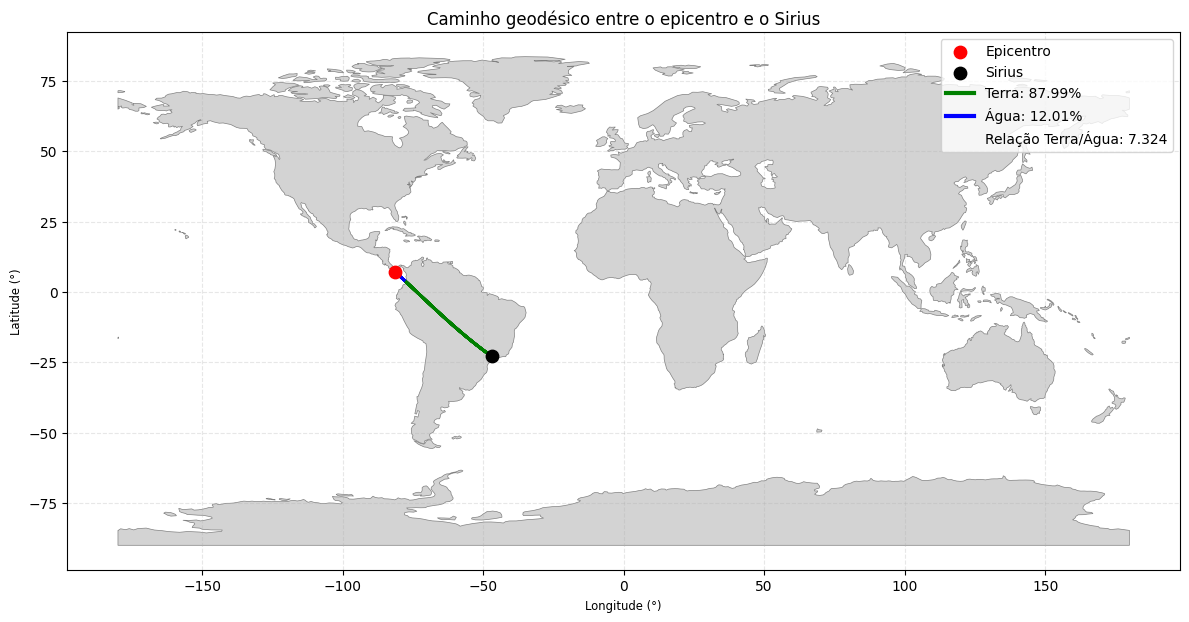

In [10]:
import geopandas as gpd
from shapely.geometry import Point
from pyproj import Geod
import matplotlib.pyplot as plt
import numpy as np
from Scripts.module import POS_LAT_SIRIUS, POS_LON_SIRIUS

land_gdf = gpd.read_file(
    "data/geographic/land/ne_110m_land.shp"
)

def calculate_earth_water_ratio(
    latitude,
    longitude,
    sirius_latitude=POS_LAT_SIRIUS,
    sirius_longitude=POS_LON_SIRIUS,
    land_gdf=land_gdf,
    n_points=1000,
    plot=False,
):
    """
    Calculate the proportion of land and water along the geodesic
    path between an earthquake epicenter and the Sirius station.

    Parameters
    ----------
    latitude : float
        Latitude of the earthquake epicenter, in degrees.
    longitude : float
        Longitude of the earthquake epicenter, in degrees.
    sirius_latitude : float, optional
        Latitude of the Sirius station, in degrees.
        Default is POS_LAT_SIRIUS.
    sirius_longitude : float, optional
        Longitude of the Sirius station, in degrees.
        Default is POS_LON_SIRIUS.
    land_gdf : geopandas.GeoDataFrame, optional
        GeoDataFrame containing the world's land polygons.
        Default is the Natural Earth land dataset.
    n_points : int, optional
        Number of points used to sample the geodesic path.
        Default is 1000.
    plot : bool, optional
        If True, plots the geodesic path between the earthquake
        epicenter and the Sirius station, distinguishing land
        and water segments. Default is False.

    Returns
    -------
    dict
        Dictionary containing the total distances over land and
        water, their respective fractions, and the land-to-water
        distance ratio.

        The returned dictionary contains:

        - ``land_distance`` : float
            Distance traveled over land, in meters.
        - ``water_distance`` : float
            Distance traveled over water, in meters.
        - ``total_distance`` : float
            Total geodesic distance between the epicenter and
            the Sirius station, in meters.
        - ``land_fraction`` : float
            Fraction of the total path traveled over land.
        - ``water_fraction`` : float
            Fraction of the total path traveled over water.
        - ``earth_water_ratio`` : float
            Ratio between the distance traveled over land and
            the distance traveled over water.
    """

    land_gdf = land_gdf.to_crs("EPSG:4326")

    geod = Geod(ellps="WGS84")

    intermediate_points = geod.npts(
        longitude,
        latitude,
        sirius_longitude,
        sirius_latitude,
        n_points - 2,
    )

    coordinates = [
        (longitude, latitude),
        *intermediate_points,
        (sirius_longitude, sirius_latitude),
    ]

    segment_distances = []

    for (lon1, lat1), (lon2, lat2) in zip(
        coordinates[:-1],
        coordinates[1:]
    ):
        distance, _, _ = geod.inv(
            lon1,
            lat1,
            lon2,
            lat2,
        )

        segment_distances.append(distance)

    segment_distances = np.asarray(segment_distances)

    midpoints = []

    for (lon1, lat1), (lon2, lat2) in zip(
        coordinates[:-1],
        coordinates[1:]
    ):
        lon_mid = (lon1 + lon2) / 2
        lat_mid = (lat1 + lat2) / 2

        midpoints.append(Point(lon_mid, lat_mid))

    midpoint_gdf = gpd.GeoDataFrame(
        geometry=midpoints,
        crs="EPSG:4326",
    )

    land_union = land_gdf.geometry.union_all()

    is_land = midpoint_gdf.geometry.within(
        land_union
    ).to_numpy()

    land_distance = segment_distances[is_land].sum()
    water_distance = segment_distances[~is_land].sum()

    total_distance = land_distance + water_distance

    land_fraction = land_distance / total_distance
    water_fraction = water_distance / total_distance

    if water_distance > 0:
        earth_water_ratio = land_distance / water_distance
    else:
        earth_water_ratio = np.inf

    if plot:

        _, ax = plt.subplots(figsize=(12, 7))

        # Continents
        land_gdf.plot(
            ax=ax,
            facecolor="lightgray",
            edgecolor="gray",
            linewidth=0.5,
        )

        # Geodesic path
        for i, ((lon1, lat1), (lon2, lat2)) in enumerate(
            zip(coordinates[:-1], coordinates[1:])
        ):
            color = "green" if is_land[i] else "blue"

            ax.plot(
                [lon1, lon2],
                [lat1, lat2],
                color=color,
                linewidth=2,
            )

        # Epicenter
        ax.scatter(
            longitude,
            latitude,
            color="red",
            s=80,
            zorder=5,
            label="Epicentro",
        )

        # Sirius station
        ax.scatter(
            sirius_longitude,
            sirius_latitude,
            color="black",
            s=80,
            zorder=5,
            label="Sirius",
        )

        # Legend entries for the calculated ratios
        ax.plot(
            [],
            [],
            color="green",
            linewidth=3,
            label=f"Terra: {land_fraction:.2%}",
        )

        ax.plot(
            [],
            [],
            color="blue",
            linewidth=3,
            label=f"Água: {water_fraction:.2%}",
        )

        ax.plot(
            [],
            [],
            color="none",
            label=f"Relação Terra/Água: {earth_water_ratio:.3f}",
        )

        ax.set_xlabel("Longitude (°)")
        ax.set_ylabel("Latitude (°)")

        ax.set_title(
            "Caminho geodésico entre o epicentro e o Sirius"
        )

        ax.legend()

        ax.grid(
            linestyle="--",
            alpha=0.3,
        )

        plt.tight_layout()
        plt.show()

    return {
        "land_distance": land_distance,
        "water_distance": water_distance,
        "total_distance": total_distance,
        "land_fraction": land_fraction,
        "water_fraction": water_fraction,
        "earth_water_ratio": earth_water_ratio,
    }
    
water_earth_ratio = calculate_earth_water_ratio(event_data["latitude"],event_data["longitude"], plot=True)

Vamos também verificar a placa tectônica de origem do terremoto. Para isso, utilizaremos um shapefile que contém informações sobre as placas tectônicas do planeta, disponibilizado pelo rpositório da referência [[2](#referencias)]. A partir desse shapefile, podemos determinar em qual placa tectônica o ponto do terremoto está localizado, considerando as 7 grandes placas tectônicas do planeta.

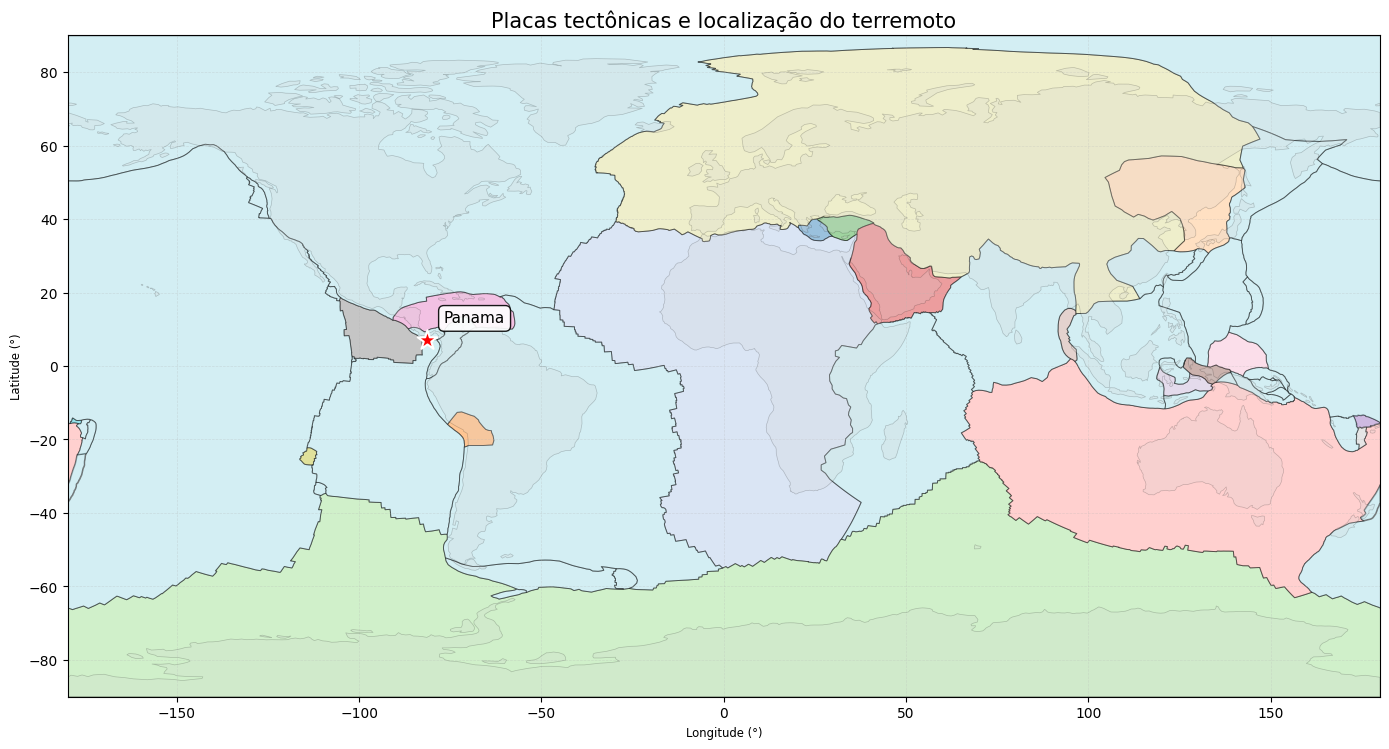

In [11]:
plates_gdf = gpd.read_file(
    "data/geographic/plates/PB2002_plates.shp"
)

def get_tectonic_plate(
    latitude,
    longitude,
    plates_gdf=plates_gdf,
    land_gdf=land_gdf,
    plot=False,
):
    """
    Identifica a placa tectônica na qual está localizado um ponto.

    Parameters
    ----------
    latitude : float
        Latitude do ponto, em graus.
    longitude : float
        Longitude do ponto, em graus.
    plates_gdf : geopandas.GeoDataFrame
        GeoDataFrame contendo os polígonos das placas tectônicas.
    land_gdf : geopandas.GeoDataFrame
        GeoDataFrame contendo os polígonos continentais.
    plot : bool, optional
        Se True, plota o mapa-múndi com as placas, continentes
        e o ponto do terremoto. Default is False.

    Returns
    -------
    str or None
        Nome da placa tectônica que contém o ponto.
    """

    point = Point(longitude, latitude)

    plates_gdf = plates_gdf.to_crs("EPSG:4326")
    land_gdf = land_gdf.to_crs("EPSG:4326")

    containing_plates = plates_gdf[
        plates_gdf.geometry.contains(point)
    ]

    if containing_plates.empty:
        plate_name = None
    else:
        plate_name = containing_plates.iloc[0]["PlateName"]

    if plot:
        fig, ax = plt.subplots(figsize=(14, 8))

        # Placas tectônicas
        plates_gdf.plot(
            ax=ax,
            column="PlateName",
            cmap="tab20",
            edgecolor="black",
            linewidth=0.7,
            alpha=0.45,
            legend=False,
        )

        # Continentes
        land_gdf.plot(
            ax=ax,
            facecolor="lightgray",
            edgecolor="black",
            linewidth=0.5,
            alpha=0.2,
            zorder=2,
        )

        # Epicentro
        gpd.GeoSeries(
            [point],
            crs="EPSG:4326",
        ).plot(
            ax=ax,
            color="red",
            edgecolor="white",
            marker="*",
            markersize=220,
            linewidth=1.5,
            zorder=5,
        )

        # Anotação
        ax.annotate(
            plate_name if plate_name is not None else "Nenhuma placa",
            xy=(longitude, latitude),
            xytext=(12, 12),
            textcoords="offset points",
            fontsize=11,
            bbox=dict(
                boxstyle="round,pad=0.35",
                facecolor="white",
                edgecolor="black",
                alpha=0.9,
            ),
            zorder=6,
        )

        ax.set_xlabel("Longitude (°)")
        ax.set_ylabel("Latitude (°)")

        ax.set_title(
            "Placas tectônicas e localização do terremoto",
            fontsize=15,
        )

        ax.set_xlim(-180, 180)
        ax.set_ylim(-90, 90)

        ax.grid(
            linestyle="--",
            linewidth=0.5,
            alpha=0.3,
        )

        plt.tight_layout()
        plt.show()

    return plate_name

origin_plate = get_tectonic_plate(
    event_data["latitude"],
    event_data["longitude"],
    plot=True,
)

Agora, basta adicionarmos essas informações ao nosso dicionário de atributos do terremoto, e teremos o dataset completo para esse evento específico.

In [12]:
event["earth_water_ratio"] = water_earth_ratio["earth_water_ratio"]
event["origin_plate"] = origin_plate

event

{'event_id': 'Panama2026-10-09T17:56:07.118061Z',
 'magnitude': np.float64(7.669379939464922),
 'magnitude_type': 'mB',
 'depth': np.float64(12.600000381469727),
 'origin_time': 2026-10-09T17:56:07.118061Z,
 'latitude': np.float64(7.194002151489258),
 'longitude': np.float64(-81.31890106201172),
 'geodesic_distance': np.float64(4994267.024231712),
 'azimuth_degree': np.float64(132.58032286132448),
 'epicenter_distance': np.float64(44.98669072016955),
 'earth_water_ratio': np.float64(7.324266119981184),
 'origin_plate': 'Panama',
 'first_arrival_time_delta': 494.88667464256287,
 'arrival_time_delta': 2750.9712789058685,
 'min_amplitude': None,
 'max_amplitude': None,
 'amplitude_std': None,
 'amplitude_region': None,
 'min_noise': None,
 'max_noise': None,
 'noise_std': None,
 'noise_region': None,
 'std_factor': None,
 'amplitude_factor': None}

O último atributo que falta calcular é o fator de amplitude, que será calculado a partir da janela de sinal e da janela de ruído. Para isso, utilizaremos as funções desenvolvidas anteriormente para calcular a amplitude do sinal e do ruído, e então calcular o fator de amplitude como a razão entre as duas.

### <a id='toc1_2_3_'></a>[Fator de amplitude](#toc0_)

Vamos criar uma função que une o cálculo da amplitude do sinal e do ruído, e retorna o fator de amplitude. A função será chamada `calculate_amplitude_factor`, e receberá como parâmetros a primeira e ultima chegada calculada. O fator de amplitude final será obtido a partir da perturbação no eixo X do BPM.

Muitos sinais de BPM possuem artefatos ou erros de medida que fazem as perturbações assumirem picos que não condizem com a interferência real gerada. Por isso, utilizaremos a difereça absoluta entre cada par de pontos do sinal, e à cortaremos no percentil de 99% para evitar anomalias.

<img src="Assets/comparação_sinais.png" width=1000/>

**Figura 1.** Comparação de diferentes tratamentos do mesmo sinal. **a)** Sinal puro com artefatos aparentes. **b)** Diferença absoluta do sinal. **c)** Diferença absoluta do sinal cortada no percentil de 99%.

In [13]:
from datetime import timedelta, datetime
import pandas as pd
import re
import os

from Scripts.module import get_archiver_data, get_initial_noise, get_signal_amplitude, plot_signal, PV_NAMES

def clean_event_id(event_id):
    match = re.search(r"^(.+?)(\d{4}-\d{2}-\d{2}T.*Z)$", event_id)

    name = match.group(1)
    timestamp = datetime.fromisoformat(
        match.group(2).replace("Z", "+00:00")
    )

    return f"{name}_{timestamp:%Y-%m-%d_%H-%M-%S-%f}"

def clean_signal_diff(signal, percentile_threshold=99):
    signal_diff = np.abs(np.diff(signal["val"]))
    threshold = np.percentile(signal_diff, percentile_threshold)

    signal_diff = np.where(
        signal_diff < threshold,
        signal_diff,
        0
    )

    signal_diff_df = pd.DataFrame({
        "secs": signal["secs"].iloc[1:].to_numpy(),
        "val": signal_diff
    })
    
    return signal_diff_df

def calculate_amplitude_factor(time_data, origin="FIRST", save_data=False, event_id=None, plot=False):
    first_arrival = to_timestamp(time_data["arrival_time"].min())
    last_arrival = to_timestamp(time_data["arrival_time"].max())
    
    from_time = first_arrival - timedelta(minutes=30).total_seconds()
    to_time = last_arrival + timedelta(minutes=30).total_seconds()
    time_delta = int(to_time - from_time)
    
    file_path_signal = f"Data/signal/{clean_event_id(event_id)}.csv"
    
    df = None

    if origin == "FIRST":
        if os.path.exists(file_path_signal):
            df = pd.read_csv(file_path_signal)
        else:
            df = get_archiver_data(
                pv=PV_NAMES[f"BPM_X"],
                from_time=from_time,
                to_time=to_time,
                optimize=time_delta,
                convert_to_iso=True
            )
    elif origin == "API":
        df = get_archiver_data(
            pv=PV_NAMES[f"BPM_X"],
            from_time=from_time,
            to_time=to_time,
            optimize=time_delta,
            convert_to_iso=True
        )
    elif origin == "CSV":
        df = pd.read_csv(file_path_signal)
    else:
        raise ValueError("Invalid origin. Use 'FIRST', 'API' or 'CSV'.")
    
    df_diff = clean_signal_diff(df)
    
    min_noise, max_noise, noise_mean_std, noise_region = get_initial_noise(df_diff)
    min_signal, max_signal, signal_std, signal_region = get_signal_amplitude(df_diff, first_arrival, last_arrival)
    
    if save_data and event_id is not None:
        df.to_csv(file_path_signal, index=False)
    
    factor_std = signal_std / noise_mean_std if noise_mean_std != 0 else float("inf")
    factor_amplitude = (max_signal - min_signal) / (max_noise - min_noise) if (max_noise - min_noise) != 0 else float("inf")
    
    if plot: plot_signal(df_diff, time_data, events_data, regions=[noise_region, signal_region])
    
    return (
        min_noise,
        max_noise,
        noise_mean_std,
        noise_region,
        min_signal,
        max_signal,
        signal_std,
        signal_region,
        factor_std,
        factor_amplitude,
    )
        
min_noise, max_noise, noise_std, noise_region, min_amplitude, max_amplitude, amplitude_std, amplitude_region, std_factor, amplitude_factor = calculate_amplitude_factor(time_data, save_data=True, event_id=event["event_id"], plot=True)

E podemos adicionar esses fatores ao nosso dicionário, assim finalizando o dataset para esse terremoto específico. A partir desse ponto, podemos repetir o processo para outros terremotos, preenchendo o dataset com informações de múltiplos eventos.

In [14]:
event.update({
    "min_noise": min_noise,
    "max_noise": max_noise,
    "noise_std": noise_std,
    "noise_region": noise_region,
    "min_amplitude": min_amplitude,
    "max_amplitude": max_amplitude,
    "amplitude_std": amplitude_std,
    "amplitude_region": amplitude_region,
    "std_factor": std_factor,
    "amplitude_factor": amplitude_factor,
})

event

{'event_id': 'Panama2026-10-09T17:56:07.118061Z',
 'magnitude': np.float64(7.669379939464922),
 'magnitude_type': 'mB',
 'depth': np.float64(12.600000381469727),
 'origin_time': 2026-10-09T17:56:07.118061Z,
 'latitude': np.float64(7.194002151489258),
 'longitude': np.float64(-81.31890106201172),
 'geodesic_distance': np.float64(4994267.024231712),
 'azimuth_degree': np.float64(132.58032286132448),
 'epicenter_distance': np.float64(44.98669072016955),
 'earth_water_ratio': np.float64(7.324266119981184),
 'origin_plate': 'Panama',
 'first_arrival_time_delta': 494.88667464256287,
 'arrival_time_delta': 2750.9712789058685,
 'min_amplitude': 0.0,
 'max_amplitude': 5724.023422692057,
 'amplitude_std': 1075.9483961207513,
 'amplitude_region': {'x0': 1791569002.0047357,
  'x1': 1791571872.9760146,
  'y0': 0.0,
  'y1': 5724.023422692057,
  'name': 'Amplitude region'},
 'min_noise': 0.1281685574549556,
 'max_noise': 177.74477245096847,
 'noise_std': np.float64(32.75420834873402),
 'noise_region'

### <a id='toc1_2_4_'></a>[Pipeline de processamento](#toc0_)

Vamos começar criando uma função que recebe uma linha do catálogo de terremotos e retorna um dicionário com os atributos calculados para aquele evento específico. A função será chamada `process_earthquake_event`, e receberá como parâmetro uma linha do catálogo de terremotos.

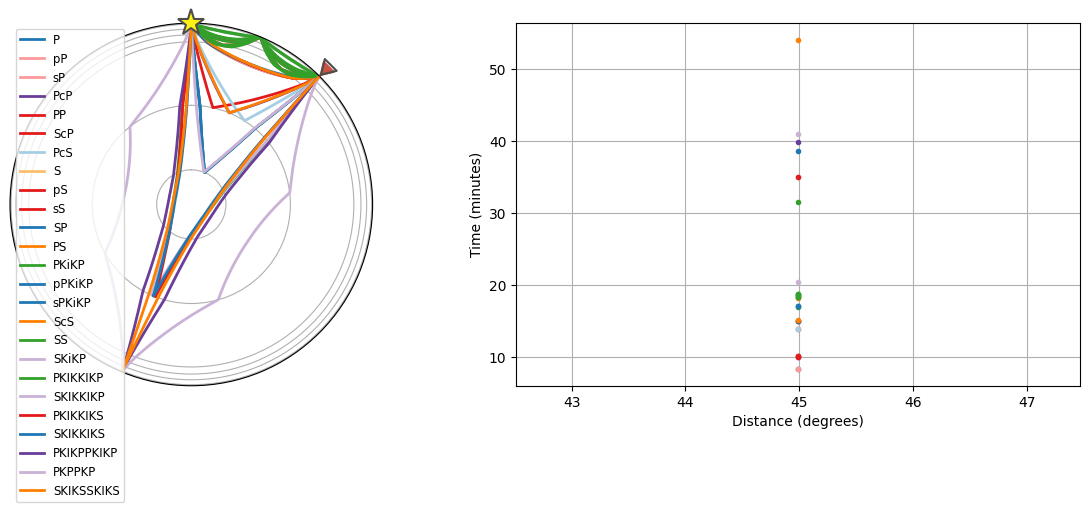

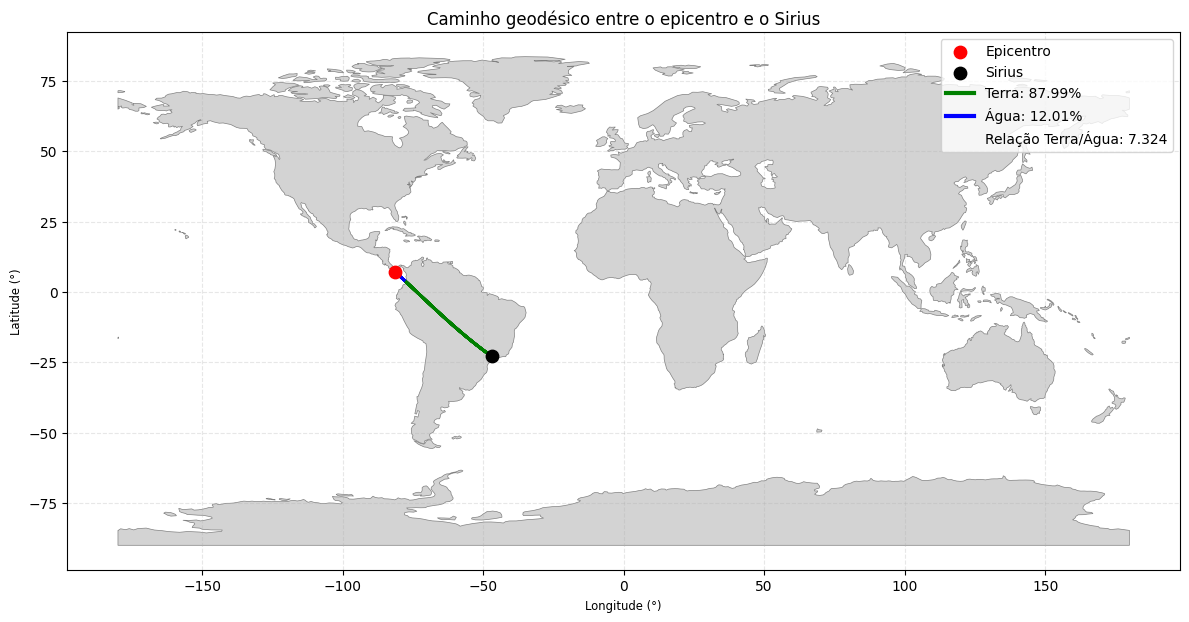

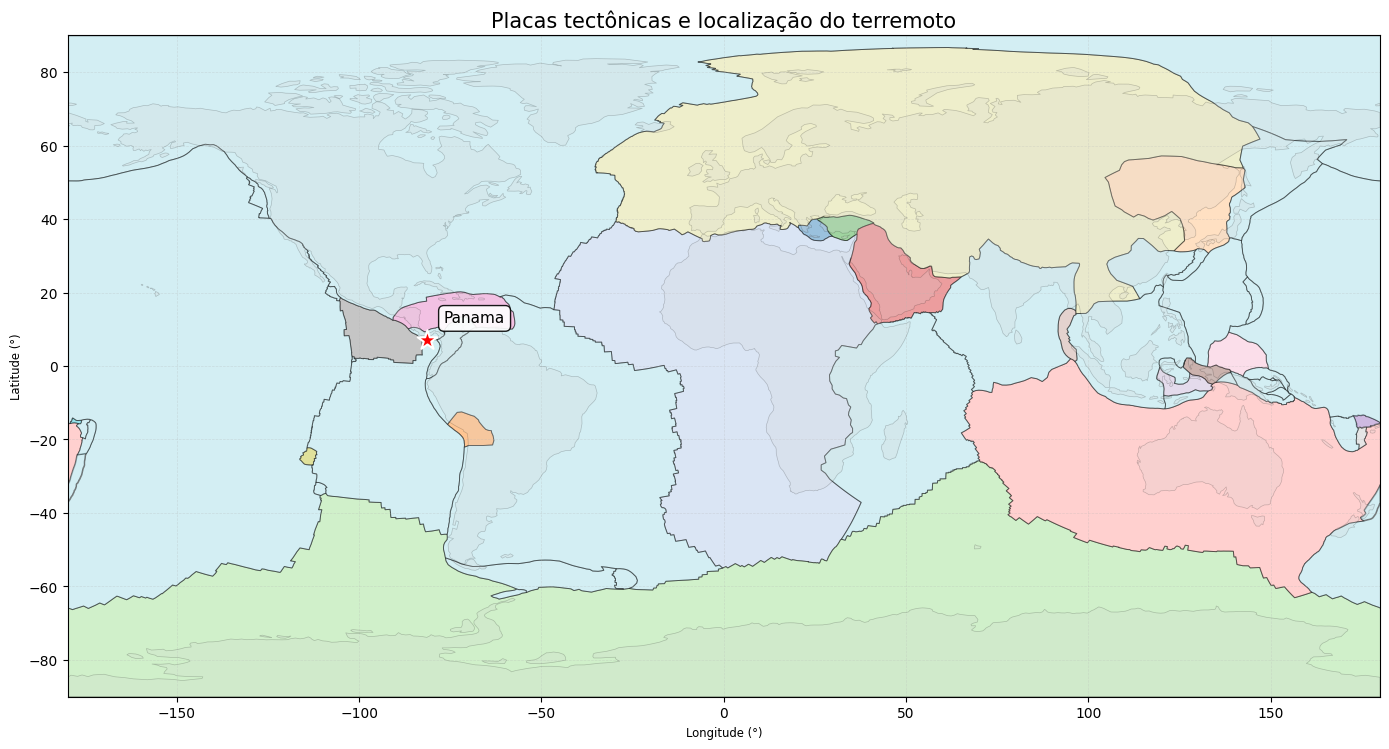

{'event_id': 'Panama2026-10-09T17:56:07.118061Z',
 'latitude': np.float64(7.194002151489258),
 'longitude': np.float64(-81.31890106201172),
 'epicenter_distance': np.float64(44.98669072016955),
 'geodesic_distance': np.float64(4994267.024231712),
 'azimuth_degree': np.float64(132.58032286132448),
 'magnitude': np.float64(7.669379939464922),
 'magnitude_type': 'mB',
 'depth': np.float64(12.600000381469727),
 'origin_time': 2026-10-09T17:56:07.118061Z,
 'first_arrival_time_delta': 494.88667464256287,
 'arrival_time_delta': 2750.9712789058685,
 'earth_water_ratio': np.float64(7.324266119981184),
 'origin_plate': 'Panama',
 'min_noise': 0.1281685574549556,
 'max_noise': 177.74477245096847,
 'noise_std': np.float64(32.75420834873402),
 'noise_region': {'x0': np.float64(1791567262.0),
  'x1': np.float64(1791567812.0),
  'y0': np.float64(-32.62603979127906),
  'y1': np.float64(210.49898079970248),
  'name': 'Noise region'},
 'min_amplitude': 0.0,
 'max_amplitude': 5724.023422692057,
 'amplitu

In [15]:

def process_earthquake_event(catalog_row, save_data=False, plot=False):
    events_data, time_data = analise_catalog([catalog_row], catalog, plotting=plot)
    event_data = events_data.iloc[0]
    
    if save_data:
        events_data.to_csv(f"Data/event_data/{clean_event_id(event_data["event_id"])}.csv", index=False)
        time_data.to_csv(f"Data/time_data/{clean_event_id(event_data["event_id"])}.csv", index=False)
    
    event = {
        "event_id": event_data["event_id"],
        "latitude": event_data["latitude"],
        "longitude": event_data["longitude"],
        "epicenter_distance": event_data["epicenter_distance"],
        "geodesic_distance": event_data["geodesic_distance"],
        "azimuth_degree": event_data["azimuth_degree"],
        "magnitude": event_data["magnitude"],
        "magnitude_type": event_data["magnitude_type"],
        "depth": event_data["depth"],
        "origin_time": event_data["origin_time"],
    }
    
    first_arrival_time = to_timestamp(time_data["arrival_time"].min())
    last_arrival_time = to_timestamp(time_data["arrival_time"].max())

    event["first_arrival_time_delta"] = first_arrival_time - to_timestamp(event_data["origin_time"])
    event["arrival_time_delta"] = last_arrival_time - first_arrival_time
    
    water_earth_ratio = calculate_earth_water_ratio(event_data["latitude"],event_data["longitude"], plot=plot)
    origin_plate = get_tectonic_plate(event_data["latitude"], event_data["longitude"], plot=plot)
    
    min_noise, max_noise, noise_std, noise_region, min_amplitude, max_amplitude, amplitude_std, amplitude_region, std_factor, amplitude_factor = calculate_amplitude_factor(time_data, save_data=save_data, event_id=event_data["event_id"], plot=plot)
    
    event.update({
        "earth_water_ratio": water_earth_ratio["earth_water_ratio"],
        "origin_plate": origin_plate,
        "min_noise": min_noise,
        "max_noise": max_noise,
        "noise_std": noise_std,
        "noise_region": noise_region,
        "min_amplitude": min_amplitude,
        "max_amplitude": max_amplitude,
        "amplitude_std": amplitude_std,
        "amplitude_region": amplitude_region,
        "std_factor": std_factor,
        "amplitude_factor": amplitude_factor,
    })
    
    return event

process_earthquake_event(events[0], save_data=True, plot=True)

### <a id='toc1_2_5_'></a>[Escolha de terremotos](#toc0_)

Agora, vamos escolher os terremotos que serão utilizados para preencher o dataset. Não acho que devemos escolher terromotos aleatórios, pois existem muitos mais casos que não interferem significativamento do que o contrário. Então, precisamos tomar cuidado na forma como vamos montar o dataset, para que ele seja representativo e balanceado. A ideia é escolher terremotos de diferentes magnitudes, profundidades e localizações geográficas, para que o modelo possa aprender a lidar com uma variedade de situações.

Acredito que podemos começar com os terremotos que sabemos que influenciaram por conta dos logs. A ideia é a seguinte:
vamos fazer um algoritmo que percorre o catálogo de logs e busca por terremotos que ocorreram próximos aos horários registrados. Então, cada uma dessas observações será processada e armazenada em um dataframe, que será o nosso dataset final, enquanto os sinais serão armazenados em arquivos separados, para que possamos utilizá-los posteriormente caso necessário.

**Nota:** Vou escolher um limite mínimo de magnitude para os terremotos que serão considerados, para evitar que eventos muito pequenos, que não influenciam significativamente nos sinais, sejam incluídos no dataset. Acredito que uma magnitude mínima de 4.0 seja adequada, mas podemos ajustar esse valor conforme necessário.

**Nota:** A janela de busca para o intervalo será entre 4 horas antes do horário previsto como início até o horário previsto como fim do evento, para garantir que estamos capturando todos os sinais relevantes.

In [16]:
from Scripts.module import sub_hours
from obspy.clients.fdsn.header import FDSNNoDataException
import traceback

df_olog = pd.read_csv("Data/olog_data.csv", index_col=0)

earthquake_data = []

for i, row in df_olog.iterrows():

    try:
        events = client.get_events(
            starttime=utc.UTCDateTime(sub_hours(row["from"], 4)),
            endtime=utc.UTCDateTime(row["to"]),
            minmagnitude=4.0,
        )
        
        print()
        print(f"Processando o LOG {df_olog.index.get_loc(i)+1}/{len(df_olog)}: {row['from']} - {row['to']}, Magnitude mínima: 5.0, Eventos encontrados: {len(events)}")
        
        for event in events:
            
            print(f"Processando o evento {event.resource_id} - Magnitude: {event.magnitudes[0].mag}, Origem: {event.origins[0].time}")
            event_data = process_earthquake_event(event, save_data=True, plot=False)
            earthquake_data.append(event_data)
            
    except FDSNNoDataException as e:
        print(
            f"Sem dados para o evento {i} - "
            f"{df_olog.index.get_loc(i)+1}/{len(df_olog)}: "
            f"{row['from']} - {row['to']}."
        )
    except Exception as e:
        print(
            f"Erro ao processar o evento {i} - "
            f"{df_olog.index.get_loc(i)+1}/{len(df_olog)}: "
            f"{row['from']} - {row['to']}. Erro: {e}"
        )
        traceback.print_exc()

Sem dados para o evento 34548 - 1/26: 2026-10-22T14:33:00.000000Z - 2026-10-22T16:33:00.000000Z.

Processando o LOG 2/26: 2026-10-09T20:25:00.000000Z - 2026-10-09T21:00:00.000000Z, Magnitude mínima: 5.0, Eventos encontrados: 8
Processando o evento smi:org.gfz-potsdam.de/geofon/usp2026tuyu - Magnitude: 6.2983126971481, Origem: 2026-10-09T20:25:39.395890Z
Processando o evento smi:org.gfz-potsdam.de/geofon/usp2026tuyr - Magnitude: 5.118514220362824, Origem: 2026-10-09T20:21:41.592678Z
Processando o evento smi:org.gfz-potsdam.de/geofon/usp2026tuys - Magnitude: 4.840051741439859, Origem: 2026-10-09T20:20:23.889385Z
Processando o evento smi:org.gfz-potsdam.de/geofon/usp2026tuxp - Magnitude: 5.288267632433557, Origem: 2026-10-09T19:48:56.323765Z
Processando o evento smi:org.gfz-potsdam.de/geofon/usp2026tuxm - Magnitude: 5.149563263837119, Origem: 2026-10-09T19:46:01.019697Z
Processando o evento smi:org.gfz-potsdam.de/geofon/usp2026tuvg - Magnitude: 6.049727232735647, Origem: 2026-10-09T18:37:

Agora vamos armazenar os terremotos que temos todos em um mesmo arquivo, para que possamos processá-los de forma mais eficiente.

In [17]:
earthquake_data = pd.DataFrame(earthquake_data)
earthquake_data.to_csv("Data/earthquake_dataset.csv", index=False)

earthquake_data

,event_id,latitude,longitude,epicenter_distance,geodesic_distance,azimuth_degree,magnitude,magnitude_type,depth,origin_time,...,min_noise,max_noise,noise_std,noise_region,min_amplitude,max_amplitude,amplitude_std,amplitude_region,std_factor,amplitude_factor
0,Panama2026-10-09T20:25:39.395890Z,7.671206,-81.304634,45.301436,5.028941e+06,132.938933,6.298313,mb,10.000000,2026-10-09T20:25:39.395890Z,...,0.124038,193.039506,37.481475,"{'x0': 1791576237.0, 'x1': 1791576787.0, 'y0':...",0.000000,458.941231,87.864057,"{'x0': 1791577977.1918666, 'x1': 1791580845.70...",2.344200,2.378976
1,Panama2026-10-09T20:21:41.592678Z,7.145816,-80.153854,44.111292,4.896569e+06,133.493594,5.118514,mb,12.480278,2026-10-09T20:21:41.592678Z,...,0.124038,241.935745,43.567619,"{'x0': 1791575990.0, 'x1': 1791576540.0, 'y0':...",0.000000,458.941231,88.054428,"{'x0': 1791577729.5039217, 'x1': 1791580608.36...",2.021098,1.897928
2,Panama2026-10-09T20:20:23.889385Z,7.908816,-80.532303,44.910195,4.985018e+06,133.739742,4.840052,mb,10.000000,2026-10-09T20:20:23.889385Z,...,0.124038,241.935745,44.689854,"{'x0': 1791575919.0, 'x1': 1791576469.0, 'y0':...",0.000000,458.941231,88.176270,"{'x0': 1791577658.5746796, 'x1': 1791580530.59...",1.973071,1.897928
3,Panama2026-10-09T19:48:56.323765Z,7.530637,-81.143005,45.088416,5.005294e+06,132.967242,5.288268,mb,4.654874,2026-10-09T19:48:56.323765Z,...,0.227360,384.157055,75.241967,"{'x0': 1791574033.0, 'x1': 1791574583.0, 'y0':...",0.075447,309.042894,44.185110,"{'x0': 1791575773.265748, 'x1': 1791578644.442...",0.587240,0.804750
4,South of Panama2026-10-09T19:46:01.019697Z,7.275383,-79.672798,43.857442,4.868093e+06,133.993399,5.149563,mb,10.000000,2026-10-09T19:46:01.019697Z,...,0.227360,384.157055,79.849409,"{'x0': 1791573847.0, 'x1': 1791574397.0, 'y0':...",0.075447,309.042894,44.641111,"{'x0': 1791575587.2811751, 'x1': 1791578468.78...",0.559066,0.804750
5,Panama2026-10-09T18:37:46.196386Z,7.352776,-80.436165,44.456794,4.934943e+06,133.413392,6.049727,mb,10.000000,2026-10-09T18:37:46.196386Z,...,0.000000,5724.023423,843.704368,"{'x0': 1791569757.0, 'x1': 1791570307.0, 'y0':...",0.030681,1463.986741,173.040154,"{'x0': 1791571497.263082, 'x1': 1791574373.361...",0.205096,0.255756
6,Panama2026-10-09T18:22:16.278310Z,7.487480,-80.217308,44.393116,4.927698e+06,133.693843,5.246443,mb,10.000000,2026-10-09T18:22:16.278310Z,...,0.642442,542.674083,72.154242,"{'x0': 1791568827.0, 'x1': 1791569377.0, 'y0':...",0.030681,5443.842459,606.303401,"{'x0': 1791570566.8356123, 'x1': 1791573443.50...",8.402879,10.043347
7,Panama2026-10-09T17:56:07.118061Z,7.194002,-81.318901,44.986691,4.994267e+06,132.580323,7.669380,mB,12.600000,2026-10-09T17:56:07.118061Z,...,0.128169,177.744772,32.754208,"{'x0': 1791567262.0, 'x1': 1791567812.0, 'y0':...",0.000000,5724.023423,1075.948396,"{'x0': 1791569002.0047357, 'x1': 1791571872.97...",32.849165,32.226849
8,Chile-Bolivia Border Region2026-10-09T10:22:08...,-20.339478,-68.578102,20.150962,2.244017e+06,100.905424,5.299287,mb,10.000000,2026-10-09T10:22:08.548996Z,...,0.235377,784.130686,139.248262,"{'x0': 1791539803.0, 'x1': 1791540353.0, 'y0':...",0.000000,42276.083820,9100.460528,"{'x0': 1791541542.8687234, 'x1': 1791544653.63...",65.354213,53.930778
9,Chile-Bolivia Border Region2026-10-09T06:41:42...,-21.546719,-68.571640,19.949547,2.221783e+06,97.660537,4.300404,mb,91.547997,2026-10-09T06:41:42.527218Z,...,0.036273,219.618598,26.612677,"{'x0': 1791526567.0, 'x1': 1791527117.0, 'y0':...",0.000000,38745.973392,8149.837927,"{'x0': 1791528307.1786652, 'x1': 1791531408.10...",306.238937,176.453061


Vamos ver como está a distribuição desses terremotos.

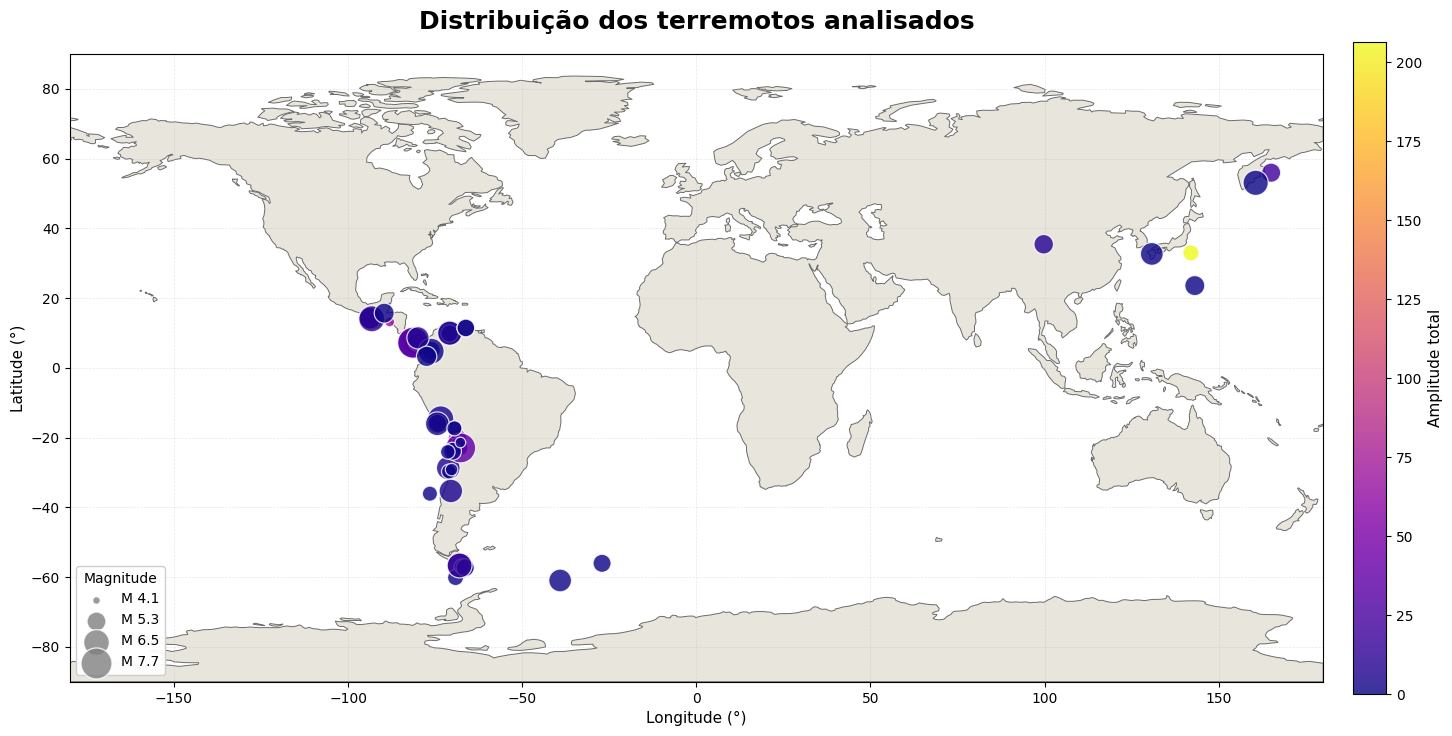

In [18]:
def plot_earthquakes(
    df,
    land_gdf,
    figsize=(16, 9),
    min_size=30,
    max_size=500,
    log_amplitude=False
):    
    data = df.dropna(
        subset=[
            "latitude",
            "longitude",
            "magnitude",
            "amplitude_factor",
        ]
    ).copy()

    land = land_gdf.to_crs("EPSG:4326")

    magnitude = data["magnitude"].to_numpy()

    mag_min = magnitude.min()
    mag_max = magnitude.max()

    if mag_min == mag_max:
        sizes = np.full(len(data), (min_size + max_size) / 2)
    else:
        sizes = np.interp(
            magnitude,
            (mag_min, mag_max),
            (min_size, max_size),
        )

    fig, ax = plt.subplots(figsize=figsize)

    land.plot(
        ax=ax,
        facecolor="#E8E5DC",
        edgecolor="#6B6B6B",
        linewidth=0.7,
        zorder=1,
    )
    
    amplitude = data["amplitude_factor"]
    
    if log_amplitude:
        mask = amplitude != 0
        amplitude = amplitude.copy()
        amplitude.loc[mask] = np.log10(amplitude.loc[mask])
        amplitude.loc[~mask] = 0

    scatter = ax.scatter(
        data["longitude"],
        data["latitude"],
        s=sizes,
        c=amplitude,
        cmap="plasma",
        alpha=0.82,
        edgecolors="white",
        linewidths=0.9,
        zorder=3,
    )

    ax.set_xlim(-180, 180)
    ax.set_ylim(-90, 90)

    ax.set_xlabel("Longitude (°)", fontsize=11)
    ax.set_ylabel("Latitude (°)", fontsize=11)

    ax.set_title(
        "Distribuição dos terremotos analisados",
        fontsize=18,
        fontweight="bold",
        pad=18,
    )

    ax.grid(
        True,
        linestyle="--",
        linewidth=0.5,
        alpha=0.3,
        zorder=0,
    )

    cbar = fig.colorbar(
        scatter,
        ax=ax,
        pad=0.02,
        shrink=0.75,
    )

    cbar.set_label(
        "Amplitude total",
        fontsize=11,
    )

    legend_magnitudes = np.linspace(
        mag_min,
        mag_max,
        4,
    )

    legend_handles = []

    for mag in legend_magnitudes:
        if mag_min == mag_max:
            size = (min_size + max_size) / 2
        else:
            size = np.interp(
                mag,
                (mag_min, mag_max),
                (min_size, max_size),
            )

        handle = ax.scatter(
            [],
            [],
            s=size,
            facecolor="gray",
            edgecolor="white",
            alpha=0.8,
            label=f"M {mag:.1f}",
        )

        legend_handles.append(handle)

    ax.legend(
        handles=legend_handles,
        title="Magnitude",
        loc="lower left",
        frameon=True,
        framealpha=0.95,
    )

    plt.tight_layout()
    plt.show()  

plot_earthquakes(earthquake_data, land_gdf)
    

Pelo visto, os terremotos que costumam ser mais sentidos pelos pesquisadores dos sirius costuma ser na região da América Latina.

Mas agora podemos pegar também outros terremotos que aconteceram em outras datas e locais para variar nosso conjunto de dados.

Tenho algumas ideias de filtros para adicionar terremotos distintos, vamos aplicá-los um por um:

#### <a id='toc1_2_5_1_'></a>[Terremotos com magnitude alta (2020-2026)](#toc0_)

Vamos buscar por terremotos que atingiram uma magnitude igual ou superior à 7.0 desde 2020.

In [19]:
events = client.get_events(
    starttime=utc.UTCDateTime("2020-01-01T00:00:00Z"),
    endtime=utc.UTCDateTime("2026-10-31T23:59:59Z"),
    minmagnitude=7.0,
)

earthquake_data = pd.read_csv("Data/earthquake_dataset.csv").to_dict(orient="records")

for i, event in enumerate(events):
    print(f"{i+1}/{len(events)} Processando o evento {event.resource_id} - Magnitude: {event.magnitudes[0].mag}, Origem: {event.origins[0].time}")
    
    try:
        event_data = process_earthquake_event(event, save_data=True, plot=False)
        earthquake_data.append(event_data)
    except Exception as e:
        print(f"{i+1}/{len(events)} - Erro ao processar o evento {event.resource_id}. Erro: {e}")
        
earthquake_data = pd.DataFrame(earthquake_data)
earthquake_data.to_csv("Data/earthquake_dataset.csv", index=False)

1/60 Processando o evento smi:org.gfz-potsdam.de/geofon/usp2026uuzx - Magnitude: 7.006438208060289, Origem: 2026-10-24T02:31:13.659376Z
2/60 Processando o evento smi:org.gfz-potsdam.de/geofon/usp2026tutw - Magnitude: 7.669379939464922, Origem: 2026-10-09T17:56:07.118061Z
3/60 Processando o evento smi:org.gfz-potsdam.de/geofon/usp2026mhpf - Magnitude: 7.221406425854974, Origem: 2026-06-24T22:04:33.349152Z
4/60 Processando o evento smi:org.gfz-potsdam.de/geofon/usp2025simi - Magnitude: 7.506574979814795, Origem: 2025-09-18T18:58:13.032385Z
5/60 Processando o evento smi:org.gfz-potsdam.de/geofon/usp2025gbpv - Magnitude: 7.494350081, Origem: 2025-03-28T06:20:55.026746Z
6/60 Processando o evento smi:org.gfz-potsdam.de/geofon/usp2025ctfk - Magnitude: 7.576820045, Origem: 2025-02-08T23:23:14.436643Z
7/60 Processando o evento smi:org.gfz-potsdam.de/geofon/usp2024yrld - Magnitude: 7.393758255, Origem: 2024-12-17T01:47:19.535340Z
8/60 Processando o evento smi:org.gfz-potsdam.de/geofon/usp2024xwu

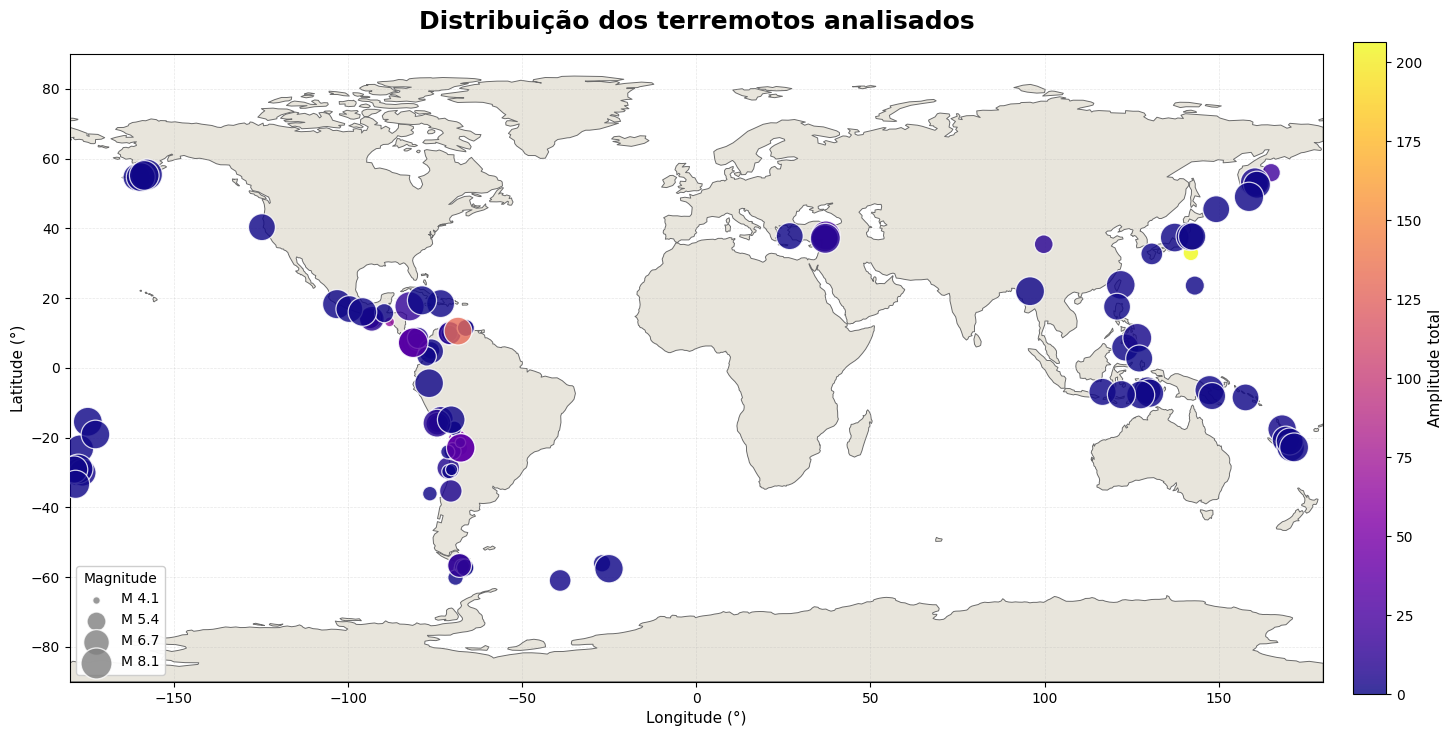

In [20]:
plot_earthquakes(earthquake_data, land_gdf)

#### <a id='toc1_2_5_2_'></a>[Terremotos na América Latina](#toc0_)

Sabemos que a maior parte dos terremotos que vai influenciar serão próximos ao sirius, provavelmente na America Latina. Vamos filtrar por essa região e amostrar uma determinada quantidade de terremotos com magnitude de pelo menos 5.0 e na região da América Latina.

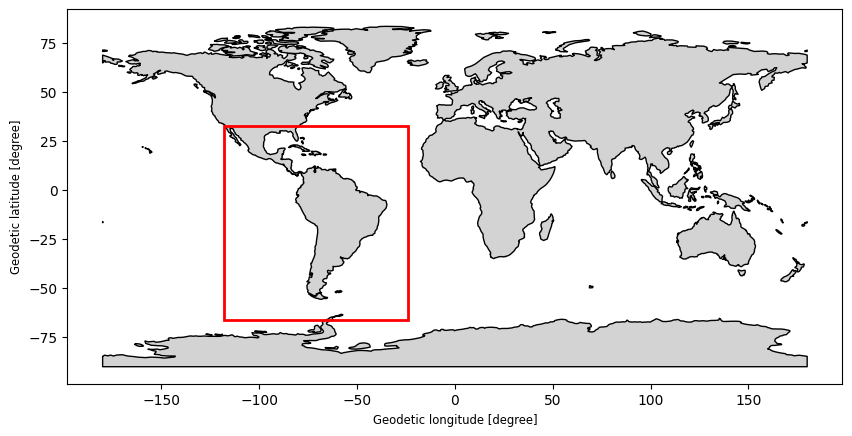

In [21]:
from matplotlib.patches import Rectangle

la_minlatitude = -66.0
la_maxlatitude = 33.0
la_minlongitude = -118.0
la_maxlongitude = -24.0

ax = land_gdf.plot(figsize=(10, 6), color="lightgray", edgecolor="black")

ax.add_patch(Rectangle(
    (la_minlongitude, la_minlatitude),
    la_maxlongitude - la_minlongitude,
    la_maxlatitude - la_minlatitude,
    fill=False,
    edgecolor="red",
    linewidth=2
))

plt.show()

In [24]:
from obspy import Catalog

events = client.get_events(
    starttime=utc.UTCDateTime("2024-01-01T00:00:00Z"),
    endtime=utc.UTCDateTime("2026-10-31T23:59:59Z"),
    minmagnitude=5.0,
    minlatitude = la_minlatitude,
    maxlatitude = la_maxlatitude,
    minlongitude = la_minlongitude,
    maxlongitude = la_maxlatitude,
)

print(f"{len(events)} eventos encontrados")

indexes = np.random.default_rng(42).choice(
    len(events),
    size=min(400, len(events)),
    replace=False
)

events = Catalog([events[i] for i in indexes])

earthquake_data = pd.read_csv("Data/earthquake_dataset.csv").to_dict(orient="records")

for i, event in enumerate(events):
    print(f"{i+1}/{len(events)} Processando o evento {event.resource_id} - Magnitude: {event.magnitudes[0].mag}, Origem: {event.origins[0].time}")
    
    try:
        event_data = process_earthquake_event(event, save_data=True, plot=False)
        earthquake_data.append(event_data)
    except Exception as e:
        print(f"{i+1}/{len(events)} - Erro ao processar o evento {event.resource_id}. Erro: {e}")
        
earthquake_data = pd.DataFrame(earthquake_data)
earthquake_data.to_csv("Data/earthquake_dataset.csv", index=False)

741 eventos encontrados
1/400 Processando o evento smi:org.gfz-potsdam.de/geofon/usp2025mwvk - Magnitude: 5.071414543517686, Origem: 2025-07-03T06:13:57.434233Z
2/400 Processando o evento smi:org.gfz-potsdam.de/geofon/usp2026admr - Magnitude: 5.30127092663212, Origem: 2026-01-02T21:48:22.404682Z
3/400 Processando o evento smi:org.gfz-potsdam.de/geofon/usp2024mgfj - Magnitude: 5.961864981, Origem: 2024-06-23T03:58:00.977327Z
4/400 Processando o evento smi:org.gfz-potsdam.de/geofon/usp2026mgvv - Magnitude: 5.090009319207303, Origem: 2026-06-24T12:16:21.074138Z
5/400 Processando o evento smi:org.gfz-potsdam.de/geofon/usp2026kmgz - Magnitude: 5.143167460040273, Origem: 2026-05-30T00:31:21.570773Z
6/400 Processando o evento smi:org.gfz-potsdam.de/geofon/usp2025ooye - Magnitude: 5.031167399, Origem: 2025-07-27T09:37:10.506856Z
7/400 Processando o evento smi:org.gfz-potsdam.de/geofon/usp2024rwbm - Magnitude: 5.488413588, Origem: 2024-09-10T23:50:39.844795Z
7/400 - Erro ao processar o evento s

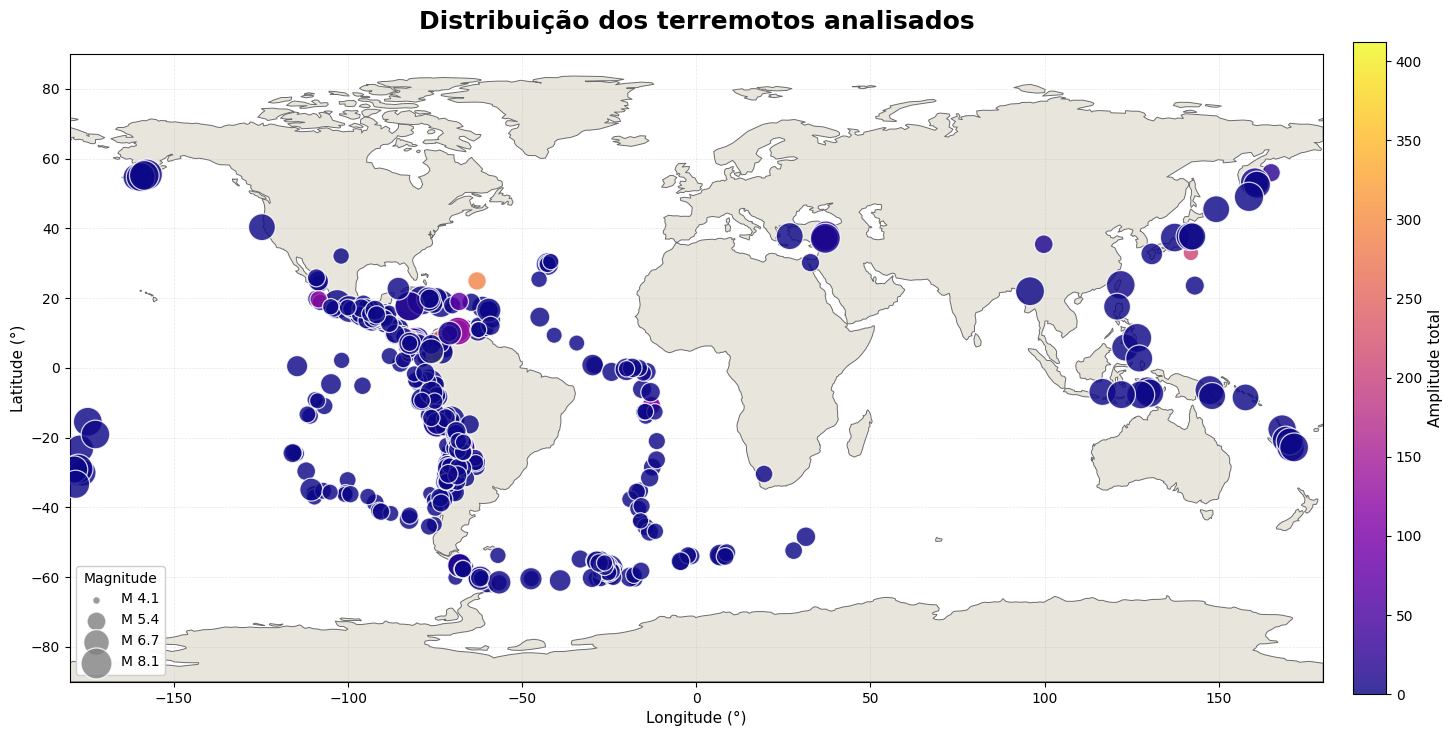

In [25]:
plot_earthquakes(earthquake_data, land_gdf)

Parece que existem algumas amplitudes muito grandes que distorcem o resto da escala. Vamos plotar o mapa com as amplitudes na escala logarítmica.

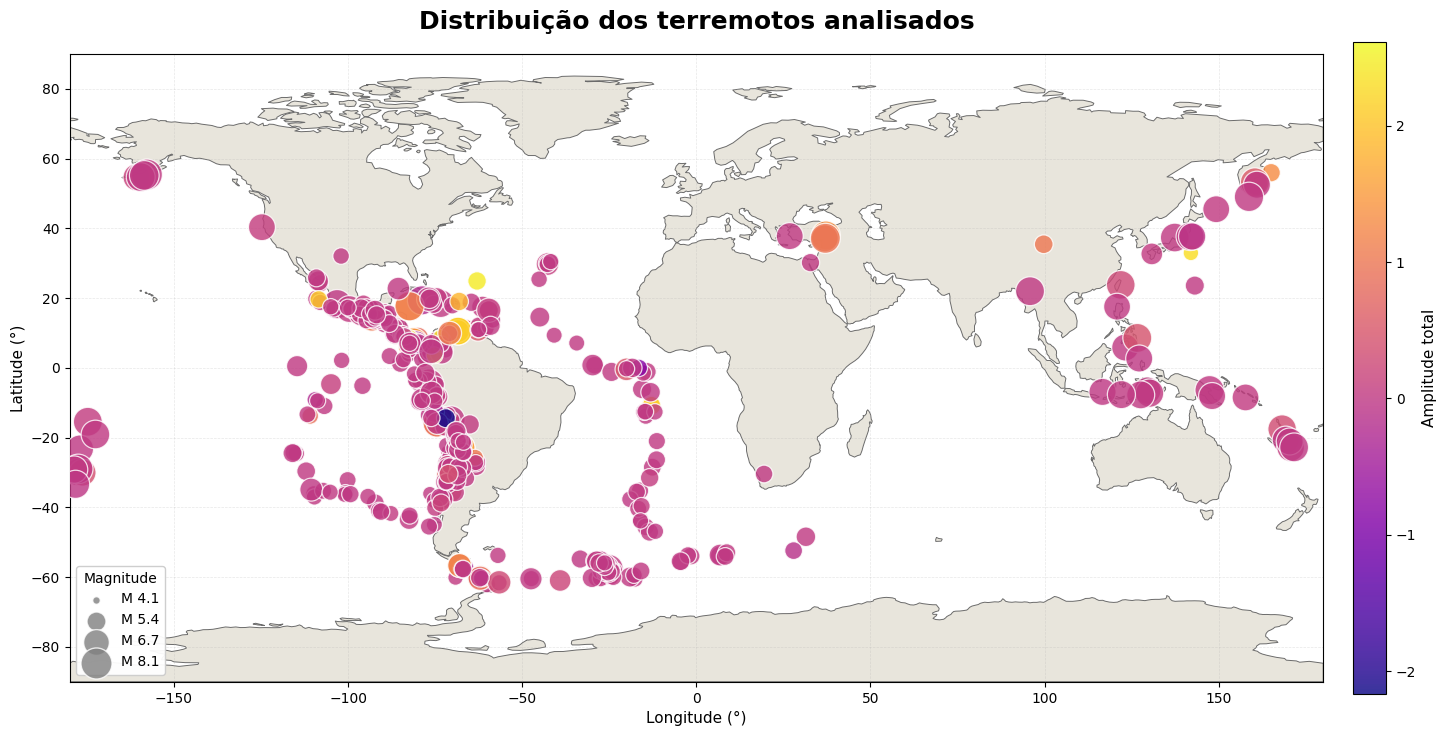

In [26]:
plot_earthquakes(earthquake_data, land_gdf, log_amplitude=True)

### <a id='toc1_2_6_'></a>[Análises finais](#toc0_)

Temos um resultado interessante. Vamos ver como é o gráfico do sinal com maior amplitude

In [27]:
event_amp = earthquake_data.sort_values("amplitude_factor", ascending=False).iloc[0]
signal_amp = pd.read_csv(f"Data/signal/{clean_event_id(event_amp["event_id"])}.csv")
time_data_amp = pd.read_csv(f"Data/time_data/{clean_event_id(event_amp["event_id"])}.csv")
event_data_amp = pd.read_csv(f"Data/event_data/{clean_event_id(event_amp["event_id"])}.csv")


plot_signal(signal_amp, time_data_amp, event_data_amp)
plot_signal(clean_signal_diff(signal_amp), time_data_amp, event_data_amp)

## <a id='toc1_3_'></a>[Conclusão](#toc0_)

Assim, conseguimos extrair vagamente o impacto do terremoto no feixe. É claro que existirão casos em que esse dado não vai estar completamente correto e corente, mas vamos começar assim para ver se os modelos utilizados conseguem abstrair pelo menos parte da informação. O próximo passo é tratar os dados obtidos para então induzir diferentes modelos e comparar as suas respectivas métricas.

<span id="referencias"></span>
## <a id='toc1_4_'></a>[Referências](#toc0_)

1. NATURAL EARTH. *110m Physical Vectors*. [S. l.]: Natural Earth, [s. d.]. Disponível em: https://www.naturalearthdata.com/downloads/110m-physical-vectors/.

2. FRAXEN. *Tectonic Plates*. GitHub, [s. d.]. Disponível em: https://github.com/fraxen/tectonicplates.
